In [20]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns


In [21]:
proc = "/nobackup/proj/comet_smmnfst/processed/"
adata = sc.read_h5ad(proc + "region1_annotated.h5ad")

In [22]:
sq.gr.spatial_neighbors(adata, coord_type="generic", n_neighs=15)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/scratch/ipykernel_587838/4014320156.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="generic", n_neighs=15)


In [23]:
conn = adata.obsp["spatial_connectivities"]
onehot = pd.get_dummies(adata.obs["cell_type"]).astype(float)
comp = np.asarray(conn @ onehot.values)
comp = comp / comp.sum(axis=1, keepdims=True)
comp = pd.DataFrame(comp, index=adata.obs_names, columns=onehot.columns)

In [24]:
niche = ad.AnnData(comp.values, obs=adata.obs[["cell_type"]].copy())
niche.var_names = comp.columns
sc.pp.neighbors(niche, n_neighbors=30, use_rep="X")
sc.tl.leiden(niche, resolution=0.4, key_added="niche", flavor="igraph", n_iterations=2)
adata.obs["niche"] = niche.obs["niche"].values
print(adata.obs["niche"].value_counts())

/scratch/ipykernel_587838/1618851319.py:2: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['Spinous keratinocyte', 'Basal keratinocyte', 'Fibroblast reticular (PI16+)', 'Basal-to-spinous keratinocyte', 'Endothelial blood']

    Inferred to be: categorical

  niche.var_names = comp.columns


niche
4     5775
7     5684
1     4257
0     3021
6     2151
8     2129
11    2027
14    1717
5     1374
12    1146
9      834
10     582
13     320
2      173
3       68
15      54
Name: count, dtype: int64


/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spat

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spat

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spat

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec 

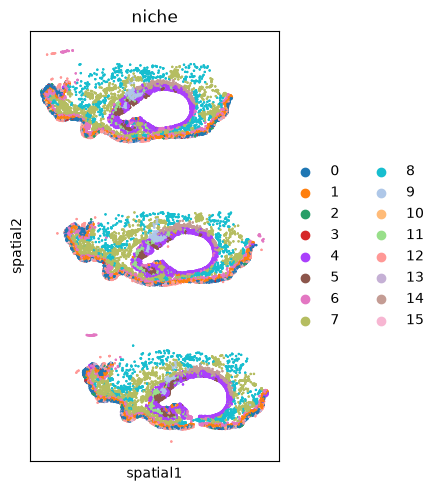

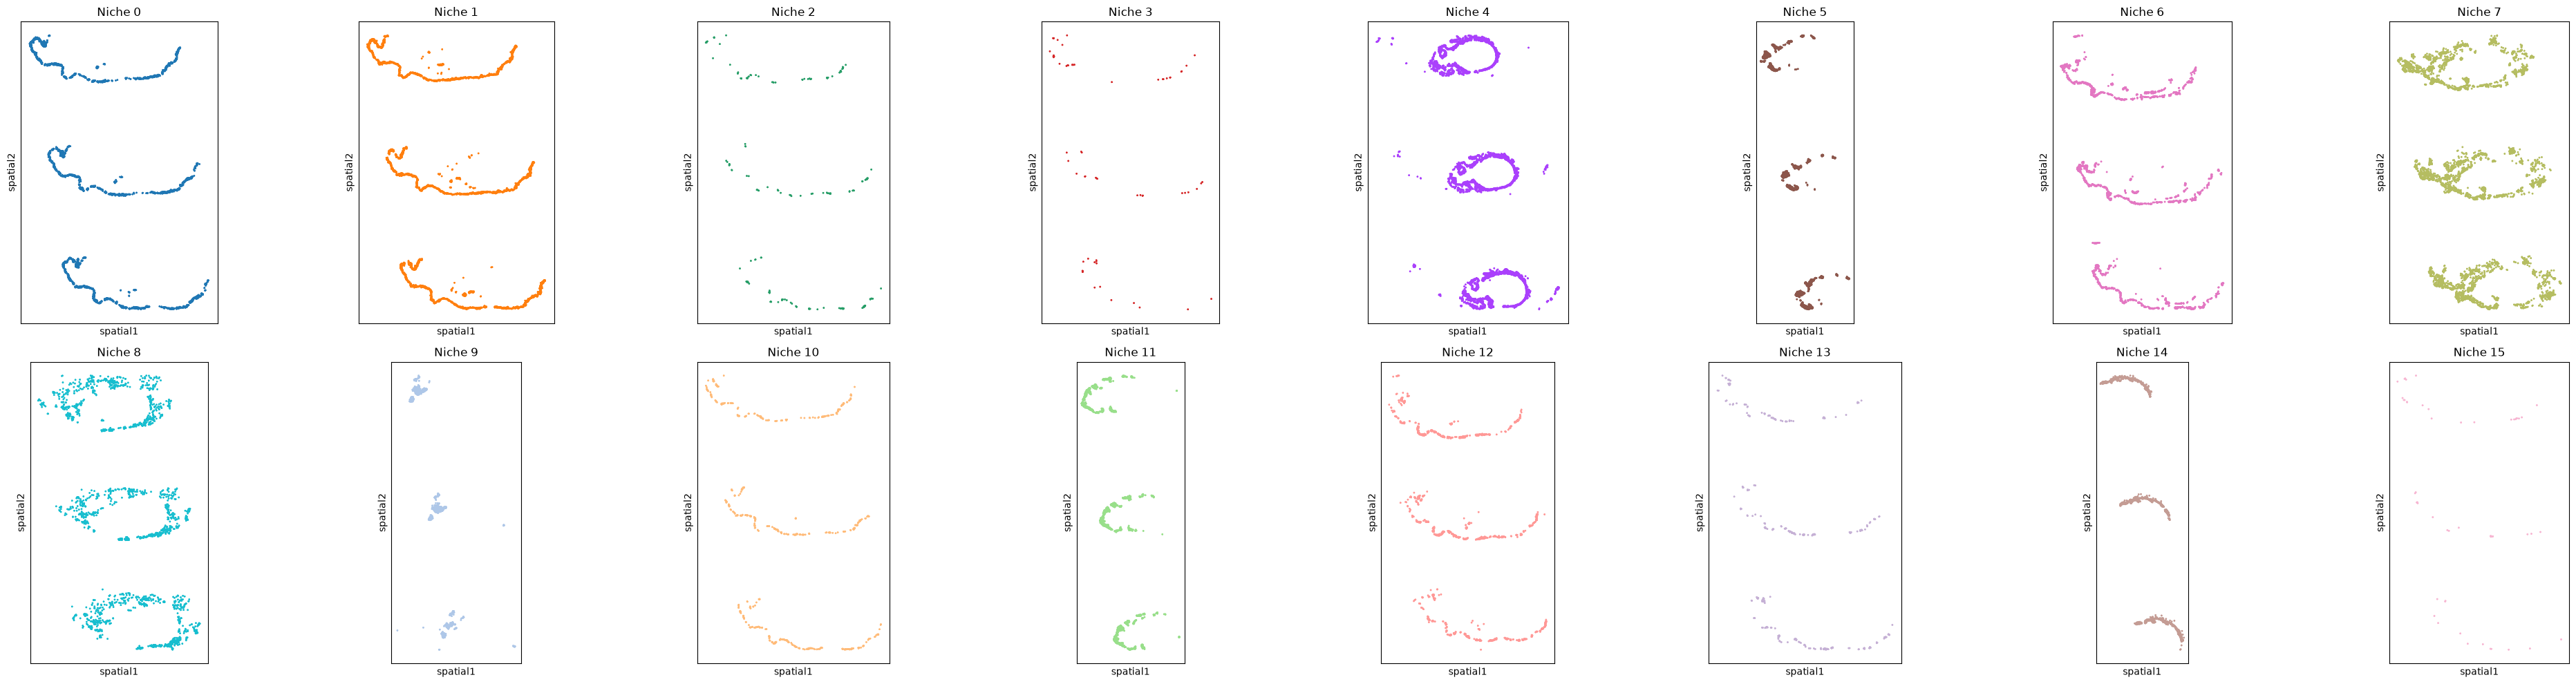

In [25]:
sq.pl.spatial_scatter(adata, color="niche", shape=None, size=2)

clusters = adata.obs["niche"].cat.categories
ncol = int(np.ceil(len(clusters) / 2))
fig, axs = plt.subplots(2, ncol, figsize=(5 * ncol, 10))
for ax, c in zip(axs.flat, clusters):
    sq.pl.spatial_scatter(adata, color="niche", groups=[c], shape=None, size=3,
                          ax=ax, title=f"Niche {c}", legend_loc=None)
for ax in axs.flat[len(clusters):]:
    ax.axis("off")
plt.tight_layout()

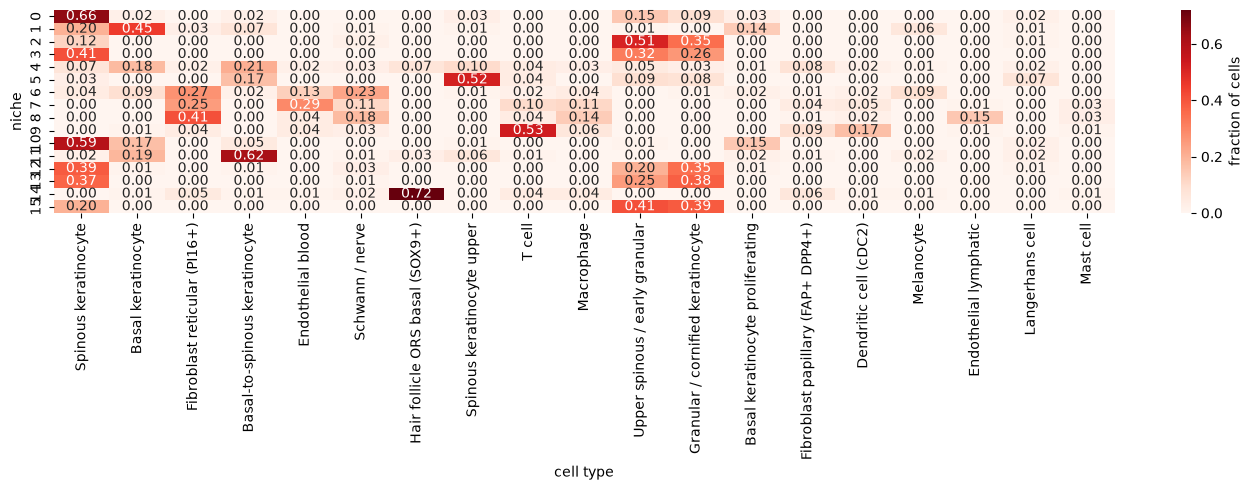

In [26]:
composition = pd.crosstab(adata.obs["niche"], adata.obs["cell_type"], normalize="index").round(2)
plt.figure(figsize=(14, 5))
sns.heatmap(composition, cmap="Reds", annot=True, fmt=".2f", cbar_kws={"label": "fraction of cells"})
plt.xlabel("cell type"); plt.ylabel("niche")
plt.tight_layout()

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


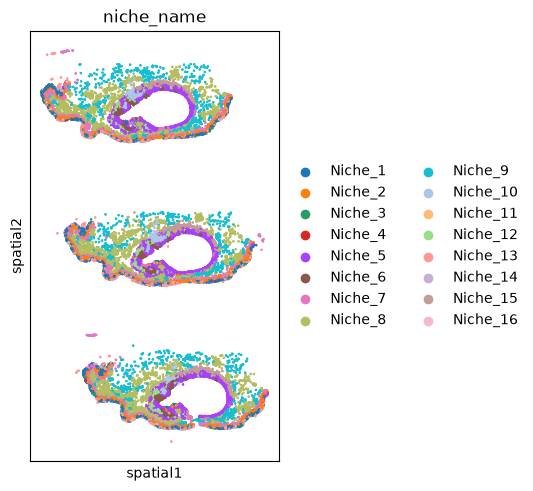

In [27]:
niche_names = {
    "0":  "Niche_1",
    "1":  "Niche_2",
    "2":  "Niche_3",
    "3":  "Niche_4",
    "4":  "Niche_5",
    "5":  "Niche_6",
    "6":  "Niche_7",
    "7":  "Niche_8",
    "8":  "Niche_9",
    "9":  "Niche_10",
    "10": "Niche_11",
    "11": "Niche_12",
    "12": "Niche_13",
    "13": "Niche_14",
    "14": "Niche_15",
    "15": "Niche_16"
}

missing = [k for k, v in niche_names.items() if v == ""]
assert not missing, f"still unnamed: {missing}"
adata.obs["niche_name"] = adata.obs["niche"].map(niche_names).astype("category")
sq.pl.spatial_scatter(adata, color="niche_name", shape=None, size=2)

In [28]:
adata.write(proc + "region1_niches.h5ad")